# Lab01 — статистика ферментативного гидролиза крахмала
**Спринт 1 + спринт 2.** Глюкоамилаза: свободная и иммобилизованная на TiO₂.

**Оговорка об исходных данных.** По согласованному изменению требований используем **все 588 записей ОП**, включая третьи значения, вычисленные по формулам. Они не являются независимыми техническими повторностями; поэтому оценки доверия строим по **сериям/условиям**, а не объявляем 588 независимыми экспериментами. Гидролиз пересчитывается из всех трёх значений.

## Содержание
- [Данные и контроль качества](#data)
- [СВ-01: оптическая плотность контроля](#rv1)
- [СВ-02: оптическая плотность пробы](#rv2)
- [СВ-03: степень гидролиза](#rv3)
- [Четыре гипотезы](#hyp)
- [Спринт 2: генератор](#generator)
- [Lab resume](#resume)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from labtools import data as ld

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize":(8,4),"axes.grid":True,"grid.alpha":0.2,"axes.spines.top":False,"axes.spines.right":False})
ALPHA = 0.05


<a id="data"></a>## Данные и контроль качества
Два исходных CSV: исходные ОП и опубликованная таблица гидролиза. Для статистики используем ОП и **единый пересчёт X по 3 значениям** для всех условий. Таблицу гидролиза сохраняем для сопоставления, а не смешиваем разные методики вычисления.

В каждой тройке два первых значения — измерения, третье часто формульно связано с ними. Для EDA учитываются все три; для статистических выводов это **не три независимых наблюдения**. Происхождение значений указано явно.

In [2]:
od = ld.add_series(ld.load_od())
original_x = ld.load_table()
triplets = ld.all_triplets(od)
hyd = ld.hydrolysis_all(triplets)
assert len(od) == 588 and len(triplets) == 196 and len(hyd) == 142
assert triplets[["a1","a2","a3"]].notna().all().all()
assert not hyd["x_pct"].isna().any()
print("ОП:",len(od),"| тройки:",len(triplets),"| X:",len(hyd))
display(od.groupby(["experiment","sample_type"]).agg(значений=("absorbance","size"), условий=("triplet_id","nunique")))
print("Формульные третьи значения включены:",len(od[od.position == 3]))
print("Пропуски ОП:",od.absorbance.isna().sum(),"| диапазон:",od.absorbance.min(),od.absorbance.max())
# Выгрузки для повторного использования в дальнейшей работе
processed=Path("data/processed");processed.mkdir(parents=True,exist_ok=True)
od.to_csv(processed/"od_all_588.csv",index=False)
triplets.to_csv(processed/"od_triplets_all3.csv",index=False)
hyd.to_csv(processed/"hydrolysis_all3.csv",index=False)

ОП: 588 | тройки: 196 | X: 142


значений  условий
experiment sample_type                   
conc       control            90       30
           free               90       30
           immobilized       150       50
kin60      control            18        6
           free               18        6
           immobilized        54       18
kin90      control            18        6
           free               18        6
           immobilized        24        8
ph         control            18        6
           free               18        6
           immobilized        18        6
temp       control            18        6
           free               18        6
           immobilized        18        6

Формульные третьи значения включены: 196
Пропуски ОП: 0 | диапазон: 0.09537 1.54521


### Статистический план
Три случайные величины: **Aконтр**, **Aпробы**, **X = 100(1−Aпробы/Aконтр)**. Стохастический источник — неопределённость приготовления, неоднородность растворов, приборный шум и условия реакции. **X формульно вычисляется, но остаётся случайной величиной как функция случайных A**. Формульное третье значение также случайно в вероятностном смысле, но зависимо от исходных двух.

Оценки параметров и распределений на смеси условий описательны. Для проверки эффектов используем спаривание и агрегирование внутри независимых постановок; при малом числе серий p-значения интерпретируем осторожно.

In [3]:
def describe(x):
    x=np.asarray(x,float)
    return pd.Series({"n":len(x),"среднее":x.mean(),"SD":x.std(ddof=1),"медиана":np.median(x),"Q1":np.quantile(x,.25),"Q3":np.quantile(x,.75),"CV":x.std(ddof=1)/abs(x.mean())})

def overview(x,name,units):
    x=np.asarray(x,float)
    fig,axs=plt.subplots(1,3,figsize=(13,3.5))
    axs[0].hist(x,bins="auto",edgecolor="white");axs[0].set(xlabel=f"{name}, {units}",ylabel="Частота")
    stats.probplot(x,dist="norm",plot=axs[1]);axs[1].set_title("Q–Q: нормальное")
    axs[2].plot(np.sort(x),np.arange(1,len(x)+1)/len(x));axs[2].set(xlabel=f"{name}, {units}",ylabel="ECDF")
    plt.tight_layout();plt.show()
    print("Шапиро–Уилк (описательно):",stats.shapiro(x))

def sampling_check(pop,n=30,seed=42):
    r=np.random.default_rng(seed);p=np.asarray(pop,float);n=min(n,len(p));
    a=r.choice(p,n,replace=True);b=r.choice(p,n,replace=False)
    return pd.DataFrame({"совокупность":describe(p),"с возвращением":describe(a),"без возвращения":describe(b)})

def consistency_demo(pop,seed=42):
    r=np.random.default_rng(seed);pop=np.asarray(pop,float);ns=[5,10,20,40,80,160,320]
    result=[]
    for count in ns:
        means=r.choice(pop,size=(800,count),replace=True).mean(axis=1)
        result.append((count,float(np.mean((means-pop.mean())**2))))
    out=pd.DataFrame(result,columns=["n","MSE оценки среднего"]);display(out)
    plt.plot(out.n,out["MSE оценки среднего"],"o-");plt.xlabel("Размер выборки n");plt.ylabel("MSE среднего");plt.show()


<a id="rv1"></a>## Random Variable 01 — ОП контроля
### Description
Случайное наблюдение Aконтр при фиксированных факторах. Во всей совокупности смешаны условия с разными концентрациями; единого нормального закона для смеси не предполагаем.
### EDA & Distribution

,"A контроля, отн. ед."
n,162.000000
среднее,1.048472
SD,0.351857
медиана,1.182655
Q1,0.842031
Q3,1.283499
CV,0.335591


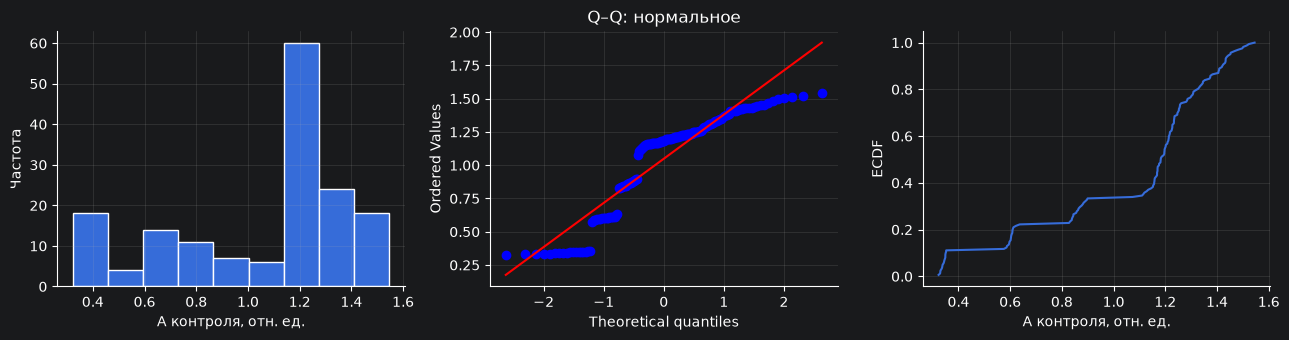

Шапиро–Уилк (описательно): ShapiroResult(statistic=np.float64(0.8657655371827809), pvalue=np.float64(7.447560469854398e-11))


,count,mean,std
substrate_pct,,,
0.25,18,0.341146,0.009072
0.50,18,0.603439,0.013686
0.75,18,0.861260,0.022762
1.00,90,1.235506,0.081379
1.25,18,1.452870,0.046093


In [4]:
a_ctrl=od.loc[od.sample_type=="control","absorbance"].to_numpy()
display(describe(a_ctrl).to_frame("A контроля, отн. ед."));overview(a_ctrl,"A контроля","отн. ед.")
display(od[od.sample_type=="control"].groupby("substrate_pct")["absorbance"].agg(["count","mean","std"]))

### Independence & Estimations
Формульная третья запись зависит от первых двух. Кроме того, результаты одной серии разделяют условия приготовления растворов: независимость отдельных строк не постулируем. Проверка зависимости A1 и A3 приведена ниже. Состоятельность выборочного среднего иллюстрируем падением MSE при увеличении n (условное моделирование выборок из эмпирической совокупности).

Corr(A1,A3) контроля: 0.9985844012594826


,совокупность,с возвращением,без возвращения
n,162.000000,30.000000,30.000000
среднее,1.048472,1.108858,1.013752
SD,0.351857,0.350385,0.365661
медиана,1.182655,1.194790,1.174785
Q1,0.842031,1.154130,0.668928
Q3,1.283499,1.255642,1.240655
CV,0.335591,0.315987,0.360701


,n,MSE оценки среднего
0,5,0.024347
1,10,0.012409
2,20,0.006558
3,40,0.002929
4,80,0.001569
5,160,0.000786
6,320,0.000371


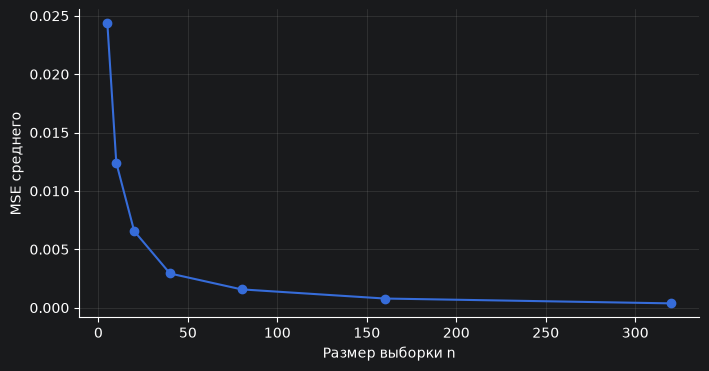

In [5]:
cc=triplets[triplets.sample_type=="control"]
print("Corr(A1,A3) контроля:",cc[["a1","a3"]].corr().iloc[0,1])
display(sampling_check(a_ctrl,n=30));consistency_demo(a_ctrl)

<a id="rv2"></a>## Random Variable 02 — ОП пробы с ферментом
### Description
Изменчивая ОП после ферментативной реакции: тип фермента, цикл, время, температура, pH и концентрация влияют на её распределение.
### EDA & Distribution

,"A пробы, отн. ед."
n,426.000000
среднее,0.764631
SD,0.367334
медиана,0.823305
Q1,0.445723
Q3,1.097634
CV,0.480407


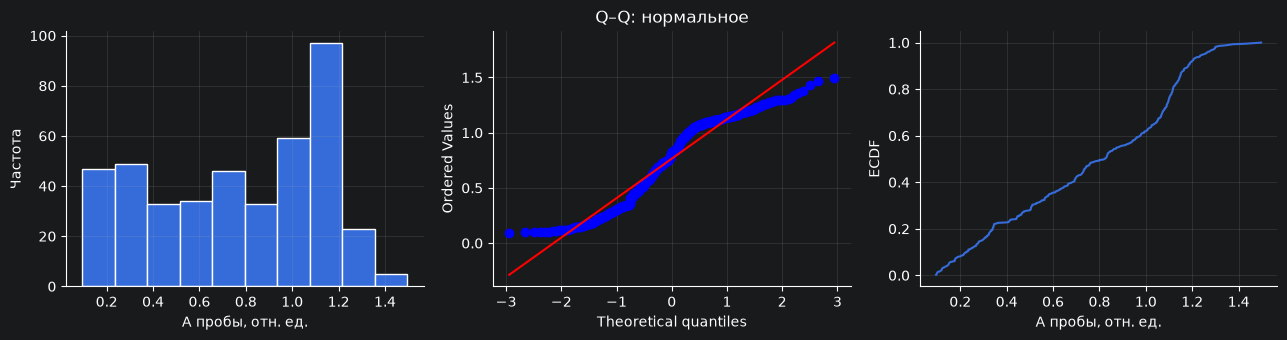

Шапиро–Уилк (описательно): ShapiroResult(statistic=np.float64(0.9339406545779786), pvalue=np.float64(8.522122419001408e-13))


count      mean       std
sample_type cycle                           
free        1        162  0.672350  0.361085
immobilized 1        162  0.684953  0.354619
            2         51  1.037825  0.253042
            3         51  1.037657  0.240468

In [6]:
a_enz=od.loc[od.sample_type!="control","absorbance"].to_numpy()
display(describe(a_enz).to_frame("A пробы, отн. ед."));overview(a_enz,"A пробы","отн. ед.")
display(od[od.sample_type!="control"].groupby(["sample_type","cycle"])["absorbance"].agg(["count","mean","std"]))

### Independence & Estimations
Поскольку у контроля и пробы общие условия, прямую корреляцию нельзя трактовать как причинную. Связь оцениваем на уровне условий, а для инференции — на уровне серий. Состоятельность проверяется эмпирически.

Корреляция контроль–проба на уровне условий: 0.7202304630187392


,совокупность,с возвращением,без возвращения
n,426.000000,50.000000,50.000000
среднее,0.764631,0.780070,0.791005
SD,0.367334,0.385117,0.381616
медиана,0.823305,0.957535,0.880092
Q1,0.445723,0.348272,0.444174
Q3,1.097634,1.104343,1.117580
CV,0.480407,0.493696,0.482444


,n,MSE оценки среднего
0,5,0.025204
1,10,0.013679
2,20,0.006435
3,40,0.003374
4,80,0.001690
5,160,0.000944
6,320,0.000423


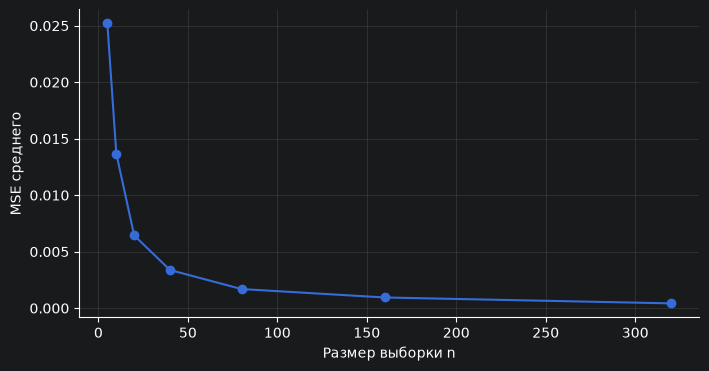

In [7]:
merged=triplets[triplets.sample_type!="control"].merge(triplets[triplets.sample_type=="control"][ ["experiment",*ld.FACTORS,"mean"] ],on=["experiment",*ld.FACTORS],suffixes=("_sample","_control"),validate="many_to_one")
print("Корреляция контроль–проба на уровне условий:",merged[["mean_sample","mean_control"]].corr().iloc[0,1])
display(sampling_check(a_enz,n=50));consistency_demo(a_enz)

<a id="rv3"></a>## Random Variable 03 — степень гидролиза X, %
### Description & math desc

$$
X = 100\left(1 -
\frac{\overline{A}_{\mathrm{проба},3}}
{\overline{A}_{\mathrm{контроль},3}}
\right)
$$
Здесь каждое среднее включает **три** значения, в том числе формульное. X зависит от случайных A; потому X — производная случайная величина. Из-за общей контрольной ОП величины X для проб при одинаковых условиях зависимы. Не следует использовать SD трёх записей как оценку неопределённости трёх независимых лабораторных повторов.

### EDA & Distribution

,"X, %"
n,142.000000
среднее,29.421436
SD,22.724061
медиана,21.494947
Q1,10.995048
Q3,41.967317
CV,0.772364


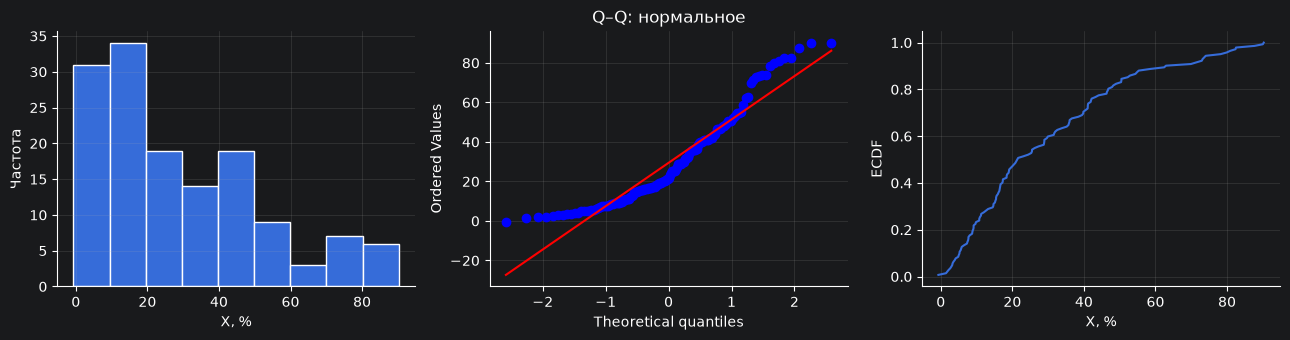

Шапиро–Уилк (описательно): ShapiroResult(statistic=np.float64(0.9067456743369056), pvalue=np.float64(6.332191391027425e-08))


count       mean     median        std
sample_type cycle                                        
free        1         54  37.245026  33.872313  22.027613
immobilized 1         54  35.984533  31.783022  21.003153
            2         17   6.689823   7.446076   3.070902
            3         17   6.454166   5.704495   3.350548

Доля X<0: 0.007042253521126761


In [8]:
display(describe(hyd.x_pct).to_frame("X, %"));overview(hyd.x_pct,"X","%")
display(hyd.groupby(["sample_type","cycle"])["x_pct"].agg(["count","mean","median","std"]))
print("Доля X<0:",np.mean(hyd.x_pct<0))

### Independence & Estimations

,совокупность,с возвращением,без возвращения
n,142.000000,40.000000,40.000000
среднее,29.421436,23.507659,32.913855
SD,22.724061,23.062192,25.416002
медиана,21.494947,15.260876,31.783022
Q1,10.995048,7.652892,11.457533
Q3,41.967317,36.142521,46.484386
CV,0.772364,0.981050,0.772198


,n,MSE оценки среднего
0,5,91.017897
1,10,51.221792
2,20,23.744971
3,40,12.603565
4,80,6.907473
5,160,3.349145
6,320,1.637753


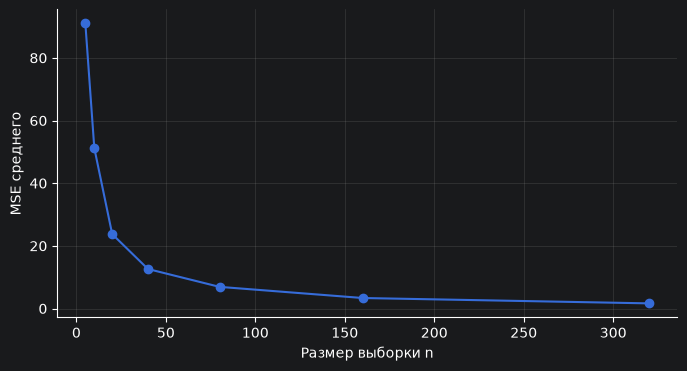

Сопоставленных наблюдений: 88


In [9]:
display(sampling_check(hyd.x_pct,n=40));consistency_demo(hyd.x_pct)
# Условия, в которых можно сравнить ферменты при равных T, pH, C, t
key=["experiment","series",*ld.FACTORS]
free=hyd[hyd.sample_type=="free"][key+["x_pct"]].rename(columns={"x_pct":"x_free"})
imm=hyd[hyd.sample_type=="immobilized"].copy()
paired=imm.merge(free,on=key,validate="many_to_one")
print("Сопоставленных наблюдений:",len(paired))

<a id="hyp"></a>## Проверка четырёх гипотез

Уровень значимости $\alpha=0{,}05$. Единица первичного анализа — **тройка** из трёх значений ОП (включая расчётное). Для каждой тройки вычисляется $\overline A=(A_1+A_2+A_3)/3$, затем степень гидролиза $X=100(1-\overline A_{\text{пр}}/\overline A_{\text{контр}})$. Формульные значения учитываются в среднем, но не считаются тремя независимыми повторностями. Для тестов усредняем эффекты в пределах экспериментальной серии. Применяется поправка Холма на четыре проверки.

1. **Калибровка без фона:** $H_0: a=0$ в $E[A_{\mathrm{контр}}|C]=a+bC$.
2. **ОП контроля не меняется со временем:** $H_0$: средний наклон временного тренда равен нулю.
3. **Накопленная эффективность иммобилизованного фермента:** для одинаковых температуры, времени, концентрации крахмала и pH сумма $X$ за циклы 1, 2 и 3 больше $X$ свободного фермента за один цикл. $H_0:E[\Delta]\leq 0$, $H_1:E[\Delta]>0$, где $\Delta=\sum_{c=1}^3 X_{\mathrm{имм},c}-X_{\mathrm{св}}$. Каждое $X$ рассчитано по **среднему тройки**. Неполные наборы циклов не включаются только в эту проверку.
4. **Различие в первом цикле:** $H_0:E[X_{\mathrm{имм},1}-X_{\mathrm{св}}]=0$, $H_1:\ne 0$ при прочих равных условиях.

Неотвержение $H_0$ не доказывает её истинность.

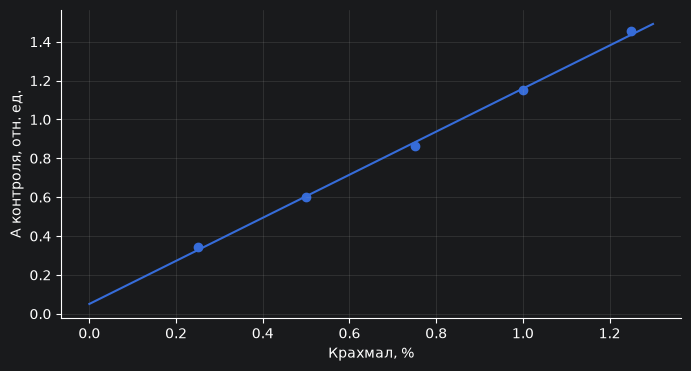

H1: a=0.05065, CI95=(np.float64(-0.00893608561544424), np.float64(0.11024591894877733)), p=0.073461, R²=0.9988


In [10]:
# H1: независимая единица калибровки — концентрационный уровень (5 средних)
cal=triplets[(triplets.sample_type=="control")&(triplets.experiment=="conc")]
cal5=cal.groupby("substrate_pct",as_index=False)["mean"].mean()
fit=stats.linregress(cal5.substrate_pct,cal5["mean"])
tcrit=stats.t.ppf(.975,len(cal5)-2)
ci1=(fit.intercept-tcrit*fit.intercept_stderr,fit.intercept+tcrit*fit.intercept_stderr)
p1=2*stats.t.sf(abs(fit.intercept/fit.intercept_stderr),len(cal5)-2)
plt.scatter(cal5.substrate_pct,cal5["mean"]);xx=np.linspace(0,1.3,100);plt.plot(xx,fit.intercept+fit.slope*xx);plt.xlabel("Крахмал, %");plt.ylabel("A контроля, отн. ед.");plt.show()
print(f"H1: a={fit.intercept:.5f}, CI95={ci1}, p={p1:.5g}, R²={fit.rvalue**2:.4f}")


In [11]:
# H2: временной дрейф средних контролей: наклон ln(A) на время в каждой серии
kin=triplets[(triplets.sample_type=="control")&(triplets.experiment.isin(["conc","kin60","kin90"]))]
slopes=kin.groupby("series").apply(lambda g: np.polyfit(g.time_min,np.log(g["mean"]),1)[0],include_groups=False).rename("slope_log_per_min")
t2=stats.ttest_1samp(slopes,0);p2=float(t2.pvalue)
display(slopes.to_frame());print(f"H2: n серий={len(slopes)}, средний наклон={slopes.mean():.6f} 1/мин, p={p2:.5g}")


,slope_log_per_min
series,
conc 0.25 %,0.000511
conc 0.5 %,0.000277
conc 0.75 %,0.000810
conc 1 %,0.002161
conc 1.25 %,0.002600
kin60,0.001158
kin90,-0.000341


H2: n серий=7, средний наклон=0.001025 1/мин, p=0.040608


In [12]:
# H3. Среднее ОП каждой тройки -> X каждого цикла -> сумма X за 3 цикла.
# Строго сопоставляем одну экспериментальную серию, температуру, pH,
# концентрацию крахмала и время реакции; свободный фермент — цикл 1.
match_keys = ["experiment", "series", "temperature_c", "ph", "substrate_pct", "time_min"]
free_h3 = hyd.loc[(hyd.sample_type == "free") & (hyd.cycle == 1),
                  match_keys + ["x_pct"]].rename(columns={"x_pct": "x_free"})
imm_h3 = hyd.loc[(hyd.sample_type == "immobilized") & hyd.cycle.isin([1, 2, 3]),
                 match_keys + ["cycle", "x_pct"]]
assert not free_h3.duplicated(match_keys).any(), "Повтор условий для свободного фермента"
assert not imm_h3.duplicated(match_keys + ["cycle"]).any(), "Повтор цикла в одних условиях"

cycle_table = imm_h3.pivot(index=match_keys, columns="cycle", values="x_pct")
cycle_table = cycle_table.reindex(columns=[1, 2, 3])
full_sets = cycle_table.dropna(subset=[1, 2, 3]).reset_index()
complete = full_sets.merge(free_h3, on=match_keys, how="inner", validate="one_to_one")
assert len(complete) > 0, "Нет полных сопоставленных троек циклов"
complete = complete.rename(columns={1: "x_imm_1", 2: "x_imm_2", 3: "x_imm_3"})
complete["x_imm_sum"] = complete[["x_imm_1", "x_imm_2", "x_imm_3"]].sum(axis=1)
complete["gain_sum"] = complete["x_imm_sum"] - complete["x_free"]
series_gain = complete.groupby("series")["gain_sum"].mean()
t3 = stats.ttest_1samp(series_gain, 0, alternative="greater")
p3 = float(t3.pvalue)
print(f"H3: полных сопоставленных условий={len(complete)}, серий={len(series_gain)}")
print(f"Средняя сумма X иммобилизованного за 3 цикла={complete.x_imm_sum.mean():.3f} %")
print(f"Среднее X свободного за 1 цикл={complete.x_free.mean():.3f} %")
print(f"Средний выигрыш по сериям={series_gain.mean():.3f} п.п., p={p3:.5g}")
display(complete[match_keys + ["x_imm_1", "x_imm_2", "x_imm_3", "x_imm_sum", "x_free", "gain_sum"]])
display(series_gain.to_frame("ΣX имм − X свобод, п.п."))
complete.to_csv(processed / "h3_complete_matched_conditions.csv", index=False)


H3: полных сопоставленных условий=17, серий=7
Средняя сумма X иммобилизованного за 3 цикла=54.593 %
Среднее X свободного за 1 цикл=42.934 %
Средний выигрыш по сериям=12.990 п.п., p=0.0041103


,experiment,series,temperature_c,ph,substrate_pct,time_min,x_imm_1,x_imm_2,x_imm_3,x_imm_sum,x_free,gain_sum
0,conc,conc 0.25 %,30,4.7,0.25,30,69.902773,2.949448,3.549319,76.401540,71.443243,4.958297
1,conc,conc 0.5 %,30,4.7,0.50,30,52.246108,9.175624,4.147588,65.569319,54.823455,10.745864
2,conc,conc 0.75 %,30,4.7,0.75,30,47.844109,5.552466,5.018900,58.415475,50.383326,8.032149
3,conc,conc 1 %,30,4.7,1.00,5,9.712264,1.452356,4.873619,16.038239,10.918899,5.119341
4,conc,conc 1 %,30,4.7,1.00,10,15.260876,8.936222,3.200370,27.397468,18.378675,9.018792
5,conc,conc 1 %,30,4.7,1.00,15,16.126481,2.184869,1.825639,20.136990,18.963684,1.173306
6,conc,conc 1 %,30,4.7,1.00,20,26.229048,5.217924,2.637020,34.083993,24.438948,9.645045
7,conc,conc 1 %,30,4.7,1.00,25,28.872360,7.738309,5.858767,42.469437,28.933487,13.535949
8,conc,conc 1 %,30,4.7,1.00,30,20.436030,6.503369,3.296709,30.236109,32.557728,-2.321618
9,conc,conc 1.25 %,30,4.7,1.25,30,35.808163,3.906070,10.748915,50.463148,19.584184,30.878964


,"ΣX имм − X свобод, п.п."
series,
conc 0.25 %,4.958297
conc 0.5 %,10.745864
conc 0.75 %,8.032149
conc 1 %,6.028469
conc 1.25 %,30.878964
kin60,15.426486
kin90,14.858450


In [13]:
# H4: первый цикл иммобилизованного против свободного в тех же условиях
p1cycle=paired[paired.cycle==1].copy()
p1cycle["difference"] = p1cycle.x_pct-p1cycle.x_free
series_diff=p1cycle.groupby("series")["difference"].mean()
t4=stats.ttest_1samp(series_diff,0);p4=float(t4.pvalue)
print(f"H4: условий={len(p1cycle)}, серий={len(series_diff)}, разность={series_diff.mean():.3f} п.п., p={p4:.5g}")
display(series_diff.to_frame("X имм,1 - X свобод, п.п."))


H4: условий=54, серий=9, разность=-1.260 п.п., p=0.14235


,"X имм,1 - X свобод, п.п."
series,
conc 0.25 %,-2.206097
conc 0.5 %,-1.238916
conc 0.75 %,1.559062
conc 1 %,-2.925727
conc 1.25 %,2.305752
kin60,-3.525248
kin90,-2.898984
ph,-3.557665
temp,1.143387


In [14]:
# Поправка Холма вручную, чтобы не требовать statsmodels
pvals=np.array([p1,p2,p3,p4]);order=np.argsort(pvals);adj=np.empty_like(pvals)
previous=0
for rank,i in enumerate(order):
    previous=max(previous,(len(pvals)-rank)*pvals[i]);adj[i]=min(1,previous)
hyp=pd.DataFrame({"гипотеза":["H1: a=0","H2: нет дрейфа контроля","H3: ΣX имм > X свобод","H4: отличие X имм,1 от свобод"],"p без поправки":pvals,"p Холм":adj,"H0 отвергается":adj<ALPHA})
display(hyp)
for _,row in hyp.iterrows():print(row["гипотеза"],"—",("H0 отвергается" if row["H0 отвергается"] else "нет оснований отвергнуть H0"))


,гипотеза,p без поправки,p Холм,H0 отвергается
0,H1: a=0,0.073461,0.146922,False
1,H2: нет дрейфа контроля,0.040608,0.121825,False
2,H3: ΣX имм > X свобод,0.004110,0.016441,True
3,"H4: отличие X имм,1 от свобод",0.142347,0.146922,False


H1: a=0 — нет оснований отвергнуть H0
H2: нет дрейфа контроля — нет оснований отвергнуть H0
H3: ΣX имм > X свобод — H0 отвергается
H4: отличие X имм,1 от свобод — нет оснований отвергнуть H0


### Интерпретация сравнений

В гипотезе H3 для каждого набора одинаковых условий ($T$, $t$, $C$, pH) сперва усредняются **все три значения ОП** в каждой тройке, включая формульное. По средним ОП рассчитывается $X$ для каждого цикла иммобилизованного фермента. Затем значения $X_1+X_2+X_3$ суммируются и сопоставляются со свободным ферментом **за один цикл** в идентичных условиях. В отчёте дополнительно приведена таблица всех полных сопоставлений. Результаты неполных наборов не удаляются из исследования в целом.

Сумма процентов гидролиза здесь — **операционный индекс накопленной активности**, а не физическая масса продукта и не итоговая конверсия одной и той же порции крахмала. Для расчёта суммарной массы нужны объёмы, количества субстрата и описание обновления среды. Циклы одного образца могут быть статистически зависимы; расчётные третьи ОП также не являются независимыми измерениями. Интерпретация ограничена этими условиями.

<a id="generator"></a># Lab01 — sprint 2
## Random 01: генератор ОП контроля
### Description, math desc
Использован **эмпирический метод обратной функции (квантильное преобразование)**. Пусть F̂(x)=n⁻¹ Σ1(Xᵢ≤x), U~Uniform(0,1), тогда Y=F̂⁻¹(U) имеет эмпирическое распределение наблюдаемой величины. Алгоритм воспроизводит наблюдаемую смесь условий **включая формульные записи**, но не создаёт новых физических экспериментов и не воспроизводит независимость сосудов.

### Code

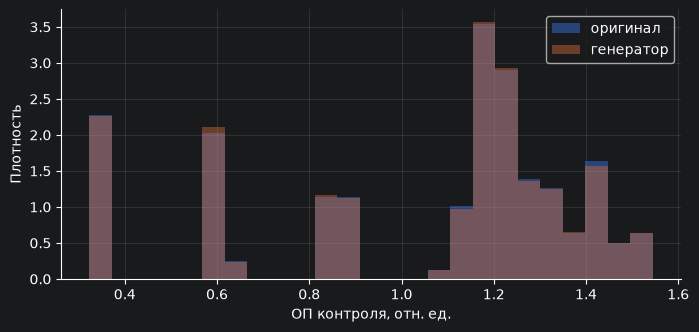

In [15]:
def empirical_inverse_generator(data,size,seed=42):
    obs=np.sort(np.asarray(data,float));r=np.random.default_rng(seed)
    u=r.random(size); idx=np.minimum((u*len(obs)).astype(int),len(obs)-1)
    return obs[idx]

generated=empirical_inverse_generator(a_ctrl,10000)
fig,ax=plt.subplots(figsize=(8,3.5));ax.hist(a_ctrl,bins=25,density=True,alpha=.5,label="оригинал");ax.hist(generated,bins=25,density=True,alpha=.45,label="генератор");ax.set(xlabel="ОП контроля, отн. ед.",ylabel="Плотность");ax.legend();plt.show()


### Tests
Частотные и моментные характеристики сопоставляем; поскольку генератор обучен на тех же данных, KS здесь — **контроль реализации**, не независимая валидация модели.

In [16]:
metric_compare=pd.concat([describe(a_ctrl).rename("Данные"),describe(generated).rename("Генератор")],axis=1)
display(metric_compare)
print("KS (контроль реализации):",stats.ks_2samp(a_ctrl,generated))
assert np.isin(generated,a_ctrl).all()
assert abs(generated.mean()-a_ctrl.mean()) < .03
assert abs(generated.std(ddof=1)-a_ctrl.std(ddof=1)) < .03
print("Автотесты генератора пройдены")

,Данные,Генератор
n,162.000000,10000.000000
среднее,1.048472,1.045523
SD,0.351857,0.350798
медиана,1.182655,1.182340
Q1,0.842031,0.838940
Q3,1.283499,1.281125
CV,0.335591,0.335524


KS (контроль реализации): KstestResult(statistic=np.float64(0.0072061728395063085), pvalue=np.float64(1.0), statistic_location=np.float64(1.23334), statistic_sign=np.int8(-1))
Автотесты генератора пройдены


### Resume и литература
Генератор сохраняет эмпирическую форму распределения, дискретность записей и смешение условий. Для порождения новых **независимых лабораторных опытов** потребовалась бы иерархическая модель, учитывающая условия, партии и формульную зависимость.

Источники: Devroye L. (1986), *Non-Uniform Random Variate Generation*, Springer, §II (inverse transform); Casella G., Berger R. L. (2002), *Statistical Inference*, Duxbury (выборочные распределения); Efron B., Tibshirani R. (1993), *An Introduction to the Bootstrap*, Chapman & Hall (ресэмплинг).

<a id="resume"></a>## Lab resume
### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| 3 случайные величины | [СВ-01](#rv1), [СВ-02](#rv2), [СВ-03](#rv3) | — | EDA, выборки, состоятельность |
| 4 гипотезы | [Проверки](#hyp) | — | Эффекты на уровне серий, Холм |
| Датчик | [Генератор](#generator) | — | Обратная эмпирическая CDF и автотесты |

**Итог.** Выводы о четырёх гипотезах вычисляются в таблице выше непосредственно из исходных CSV. Все три значения каждой тройки присутствуют во всех описательных статистиках и в расчёте X. Зависимость формульных значений явно обозначена — включение в анализ не превращает их в независимые измерения.